In [1]:
 !git clone https://github.com/evelynmyw/Medical-Hallucination-Detection.git


Cloning into 'Medical-Hallucination-Detection'...
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 5 (delta 0), reused 5 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (5/5), done.


In [2]:
%cd Medical-Hallucination-Detection

/content/Medical-Hallucination-Detection


In [3]:
!pip install -q -r requirements.txt

In [4]:
from datasets import load_dataset

labeled = load_dataset("UTAustin-AIHealth/MedHallu", "pqa_labeled")
print(labeled)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/3.74k [00:00<?, ?B/s]

pqa_labeled/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.12MB            

pqa_labeled/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Question', 'Knowledge', 'Ground Truth', 'Difficulty Level', 'Hallucinated Answer', 'Category of Hallucination'],
        num_rows: 1000
    })
})


In [7]:
df_labeled = labeled["train"].to_pandas()

print(df_labeled.shape)
print(df_labeled.columns.tolist)

(1000, 6)
<bound method IndexOpsMixin.tolist of Index(['Question', 'Knowledge', 'Ground Truth', 'Difficulty Level',
       'Hallucinated Answer', 'Category of Hallucination'],
      dtype='object')>


In [8]:
df_labeled.head()

,Question,Knowledge,Ground Truth,Difficulty Level,Hallucinated Answer,Category of Hallucination
0,Do mitochondria play a role in remodelling lac...,[Programmed cell death (PCD) is the regulated ...,Results depicted mitochondrial dynamics in viv...,medium,Mitochondria regulate the formation of perfora...,Mechanism and Pathway Misattribution
1,Landolt C and snellen e acuity: differences in...,[Assessment of visual acuity depends on the op...,"Using the charts described, there was only a s...",hard,Patients with strabismus amblyopia showed a si...,Incomplete Information
2,"Syncope during bathing in infants, a pediatric...",[Apparent life-threatening events in infants a...,"""Aquagenic maladies"" could be a pediatric form...",hard,Syncope during bathing in infants is a manifes...,Misinterpretation of #Question#
3,Are the long-term results of the transanal pul...,[The transanal endorectal pull-through (TERPT)...,Our long-term study showed significantly bette...,easy,Both transanal and transabdominal pull-through...,Misinterpretation of #Question#
4,Can tailored interventions increase mammograph...,[Telephone counseling and tailored print commu...,The effects of the intervention were most pron...,hard,Tailored text messages were found to be as eff...,Incomplete Information


In [9]:
row = df_labeled.iloc[0]

for col in df_labeled.columns:
  print(f"==== {col} ====")
  print(row[col])
  print()

==== Question ====
Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?

==== Knowledge ====
['Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transverse veins enclosing areoles. PCD occurs in the cells at the center of these areoles and progresses outwards, stopping approximately five cells from the vasculature. The role of mitochondria during PCD has been recognized in animals; however, it has been less studied during PCD in plants.'
 'The following paper elucidates the role of mitochondrial dynamics during developmentally regulated PCD in vivo in A. madagascariensis. A single areole within a window stage leaf (PCD is occurring) was divided into three areas based on the progression of PCD; cells that will not undergo PCD (NPCD), cells in early stages of P

## Task 3: Length Shortcut Check

In [10]:
# 1. Word count of each answer
df_labeled["gt_len"] = df_labeled["Ground Truth"].str.split().str.len()
df_labeled["hallu_len"] = df_labeled["Hallucinated Answer"].str.split().str.len()

# 2. Compare length statistics of the two groups
print(df_labeled[["gt_len", "hallu_len"]].describe())

# 3. Paired comparison within each question: how often is the ground truth longer?
longer = (df_labeled["gt_len"] > df_labeled["hallu_len"]).mean()
print(f"\nGround truth longer than hallucinated answer: {longer:.1%}")


            gt_len    hallu_len
count  1000.000000  1000.000000
mean     39.660000    27.801000
std      17.209432    15.145653
min       8.000000     9.000000
25%      27.000000    19.000000
50%      37.000000    23.000000
75%      49.000000    30.000000
max     126.000000   128.000000

Ground truth longer than hallucinated answer: 78.4%


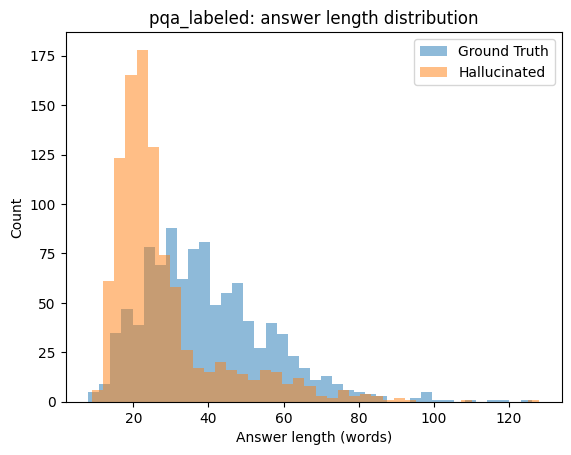

In [11]:
import matplotlib.pyplot as plt

plt.hist(df_labeled["gt_len"], bins=40, alpha=0.5, label="Ground Truth")
plt.hist(df_labeled["hallu_len"], bins=40, alpha=0.5, label="Hallucinated")
plt.xlabel("Answer length (words)")
plt.ylabel("Count")
plt.legend()
plt.title("pqa_labeled: answer length distribution")
plt.show()


## Conclusion: There Is a Clear Length Shortcut

### Answer Length Statistics

| Metric                                                                | Correct Answers | Hallucinated Answers |
| --------------------------------------------------------------------- | --------------- | -------------------- |
| Average word count                                                    | 39.7            | 27.8                 |
| Median word count                                                     | 37              | 23                   |
| Percentage of pairwise comparisons where the correct answer is longer | 78.4%           | —                    |

The distribution plot also shows this clearly: orange hallucinated answers are concentrated around 20 words, with a relatively narrow distribution. Blue correct answers are shifted noticeably to the right and have a wider distribution.

What this means:

When comparing two answers, the simple rule of "choose the longer answer" can achieve 78% accuracy without requiring any medical knowledge.

In a single-answer classification setting, this advantage may be smaller, but the model could still learn a shortcut such as "short answers are more likely to be hallucinated."

### Implications for the Next Steps

1\. Step 3: Implement a length-only baseline.

&#x20;  This means training a Logistic Regression model using only the answer's word count as a feature. BERT's performance must be compared against this baseline to determine whether it has actually learned semantic content rather than relying on answer length.

2\. Add a length-matched subset for evaluation.

&#x20;  Evaluate BERT only on questions where the two candidate answers have similar lengths (within a few words). If accuracy drops significantly on this subset, it suggests that the model relies heavily on answer length.

This analysis would also be useful to include in the Limitations section of the README.

### Additional Observation: Maximum Sequence Length

The longest answer contains 128 words. Combining the question and answer, `max_length=256` tokens should generally be sufficient.

However, adding external knowledge later may increase the input length beyond this limit. This can be addressed when Knowledge is incorporated.

## Task 4: repeat the analysis on pqa_artificial

In [12]:
artificial = load_dataset("UTAustin-AIHealth/MedHallu", "pqa_artificial")
df_artificial = artificial["train"].to_pandas()
print(df_artificial.shape)

# Questions that appear in both subsets
q_labeled = set(df_labeled["Question"])
q_artificial = set(df_artificial["Question"])
overlap = q_labeled & q_artificial
print(f"Overlapping questions: {len(overlap)}")

# Duplicate questions within each subset
print(f"Duplicates in labeled: {df_labeled['Question'].duplicated().sum()}")
print(f"Duplicates in artificial: {df_artificial['Question'].duplicated().sum()}")



pqa_artificial/train-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B / 10.3MB            

pqa_artificial/train-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

(9000, 6)
Overlapping questions: 0
Duplicates in labeled: 0
Duplicates in artificial: 1


In [13]:
# Show both rows of the duplicated question
dups = df_artificial[df_artificial["Question"].duplicated(keep=False)]
for col in ["Question", "Ground Truth", "Hallucinated Answer", "Difficulty Level"]:
    print(f"===== {col} =====")
    for val in dups[col]:
        print("-", val)
    print()

# Re-check overlap after normalizing case and whitespace
norm = lambda s: s.str.lower().str.strip()
print("Overlap (normalized):", len(set(norm(df_labeled["Question"])) & set(norm(df_artificial["Question"]))))
print("Duplicates in artificial (normalized):", norm(df_artificial["Question"]).duplicated().sum())



===== Question =====
- Does mOLECULAR CHARACTERISATION AND ANTIMICROBIAL RESISTANCE PATTERNS OF ESCHERICHIA COLI isolate FROM GOATS SLAUGHTERED IN PARTS OF KENYA?
- Does mOLECULAR CHARACTERISATION AND ANTIMICROBIAL RESISTANCE PATTERNS OF ESCHERICHIA COLI isolate FROM GOATS SLAUGHTERED IN PARTS OF KENYA?

===== Ground Truth =====
- This study demonstrated that there is a significant level of antimicrobial resistance in pathogenic E. coli isolated from goat meat from Huruma and Kiserian abattoir. This indicates that goat meat from abattoirs could pose a risk of transmission of pathogenic antibiotic resistant strains to human. Poor hygienic standards and indiscriminate use of antimicrobials are the two main reasons for the presence of resistant pathogens in goat carcasses.
- This study demonstrated that there is a significant level of antimicrobial resistance in pathogenic E. coli isolated from goat meat from Huruma and Kiserian abattoir. This indicates that goat meat from abattoirs could

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def length_report(df, name):
    """Compare word counts of ground-truth vs hallucinated answers."""
    # Local variables, so the input DataFrame is not modified
    gt_len = df["Ground Truth"].str.split().str.len()
    hallu_len = df["Hallucinated Answer"].str.split().str.len()

    # Summary statistics
    print(f"===== {name} (n={len(df)}) =====")
    stats = pd.DataFrame({"ground_truth": gt_len, "hallucinated": hallu_len}).describe()
    print(stats.round(1))

    # Paired comparison
    longer = (gt_len > hallu_len).mean()
    print(f"\nGround truth longer than hallucinated answer: {longer:.1%}\n")

    # Histogram with shared bins so bar widths match
    lo = min(gt_len.min(), hallu_len.min())
    hi = max(gt_len.max(), hallu_len.max())
    bins = np.linspace(lo, hi, 41)

    plt.figure(figsize=(7, 4))
    plt.hist(gt_len, bins=bins, alpha=0.5, label="Ground Truth")
    plt.hist(hallu_len, bins=bins, alpha=0.5, label="Hallucinated")
    plt.xlabel("Answer length (words)")
    plt.ylabel("Count")
    plt.title(f"{name}: answer length distribution")
    plt.legend()
    plt.show()


===== pqa_labeled (n=1000) =====
       ground_truth  hallucinated
count        1000.0        1000.0
mean           39.7          27.8
std            17.2          15.1
min             8.0           9.0
25%            27.0          19.0
50%            37.0          23.0
75%            49.0          30.0
max           126.0         128.0

Ground truth longer than hallucinated answer: 78.4%



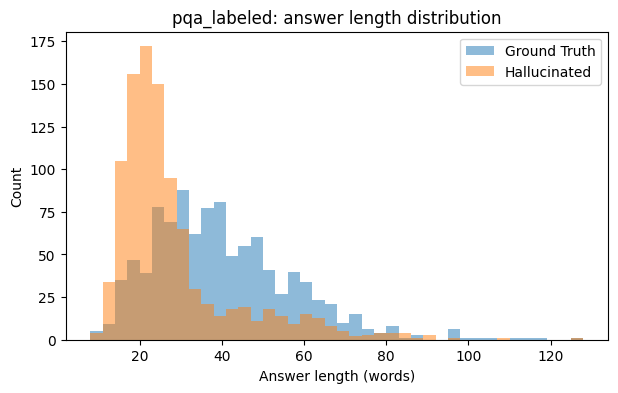

===== pqa_artificial (n=9000) =====
       ground_truth  hallucinated
count        9000.0        9000.0
mean           37.5          27.7
std            18.6          16.9
min             1.0           1.0
25%            25.0          18.0
50%            34.0          22.0
75%            46.0          30.0
max           263.0         196.0

Ground truth longer than hallucinated answer: 73.4%



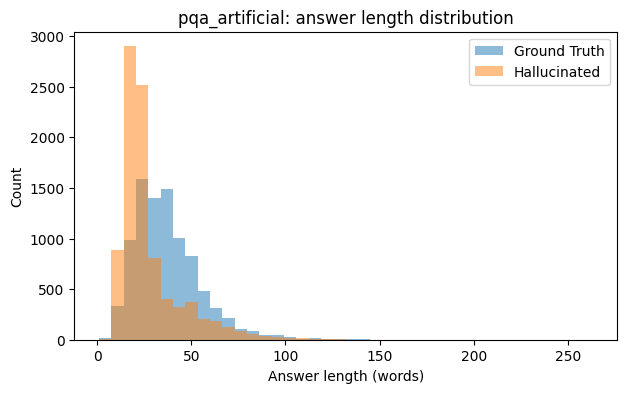

In [15]:
import pandas as pd

length_report(df_labeled, "pqa_labeled")
length_report(df_artificial, "pqa_artificial")


In [16]:
gt_len = df_artificial["Ground Truth"].str.split().str.len()
hallu_len = df_artificial["Hallucinated Answer"].str.split().str.len()

# 1. Very short answers
short = df_artificial[(gt_len <= 3) | (hallu_len <= 3)]
print(f"Rows with an answer of <= 3 words: {len(short)}")
print(short[["Question", "Ground Truth", "Hallucinated Answer"]].head(10).to_string())

# 2. Long answers that may be truncated
print(f"\nGround truth > 150 words: {(gt_len > 150).sum()}")
print(f"Hallucinated > 150 words: {(hallu_len > 150).sum()}")


Rows with an answer of <= 3 words: 5
                                                                                                                                            Question                                                                                                                                                                 Ground Truth                                                                                                                   Hallucinated Answer
2430                          Does vSL # 3 probiotic treatment decrease bacterial translocation in rats with carbon tetrachloride-induced cirrhosis?  VSL#3 decreases bacterial translocation, the pro-inflammatory state and ileal oxidative damage and increases ileal occludin expression in rats with experimental cirrhosis.                                                                                                                                   VSL
2999                             Is pancreatitis fr

In [17]:
for idx, row in short.iterrows():
    print(f"----- row {idx} -----")
    print(f"GT ({len(row['Ground Truth'].split())} words): {row['Ground Truth']}")
    print(f"Hallu ({len(row['Hallucinated Answer'].split())} words): {row['Hallucinated Answer']}")
    print()


----- row 2430 -----
GT (21 words): VSL#3 decreases bacterial translocation, the pro-inflammatory state and ileal oxidative damage and increases ileal occludin expression in rats with experimental cirrhosis.
Hallu (1 words): VSL

----- row 2999 -----
GT (3 words): Single-center, retrospective study.
Hallu (4 words): Multicenter, prospective cohort study.

----- row 3361 -----
GT (2 words): Caucasian ethnicity.
Hallu (19 words): Gender differences in scalp hair growth rates are significantly influenced by hormonal levels, even in pattern hair loss conditions.

----- row 3985 -----
GT (2 words): Single-center experience.
Hallu (2 words): Multi-center meta-analysis.

----- row 4676 -----
GT (1 words): P<0.05.
Hallu (9 words): The effect is mediated through platelet-activating factor (PAF) receptors.



In [18]:
one_word = (gt_len <= 1) | (hallu_len <= 1)
print(f"Rows with a 1-word answer: {one_word.sum()}")
print(df_artificial.loc[one_word, ["Ground Truth", "Hallucinated Answer"]].to_string())


Rows with a 1-word answer: 2
                                                                                                                                                                     Ground Truth                                                         Hallucinated Answer
2430  VSL#3 decreases bacterial translocation, the pro-inflammatory state and ileal oxidative damage and increases ileal occludin expression in rats with experimental cirrhosis.                                                                         VSL
4676                                                                                                                                                                      P<0.05.  The effect is mediated through platelet-activating factor (PAF) receptors.


## Findings
- Each row = one question with one ground-truth and one hallucinated answer → split by row (question) before expanding into samples.
- Fields: Question, Knowledge (list of passages), Ground Truth, Hallucinated Answer, Difficulty Level, Category of Hallucination.
- No question overlap between pqa_labeled and pqa_artificial. One duplicated question in pqa_artificial (same ground truth, different hallucinated answers) → drop one.
- **Length shortcut**: ground truth is longer than the hallucinated answer in 78.4% (labeled) / 73.4% (artificial) of pairs. Models must be compared against a length-only baseline.
- Corrupted rows: 2 rows in pqa_artificial have a single-word answer (truncated generation "VSL", non-answer "P<0.05.") → dropped. Other short answers (e.g. "Single-center, retrospective study.") are legitimate and kept.
